In this tutorial we will show how ElectroKitty works with data, we will not be fitting the data just yet, that is reserved for a separate tutorial. Here we will generate some data, save it and see how we can import it into ElectroKitty to work with.

# Generating data and saving it

Again we start off by importing some libraries...

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from electrokitty import ElectroKitty

Now let us create some data for us to play around with. A good reaction to play around with would be something like HER on a Pt electrode. We know that his reaction follows a Volmer-Tafel mechanism, so let us try and simulate a voltammogram that looks something like what we would actually measure. 

If you have followed the tutorials so far, the code to simulate the reaction should be obvious.

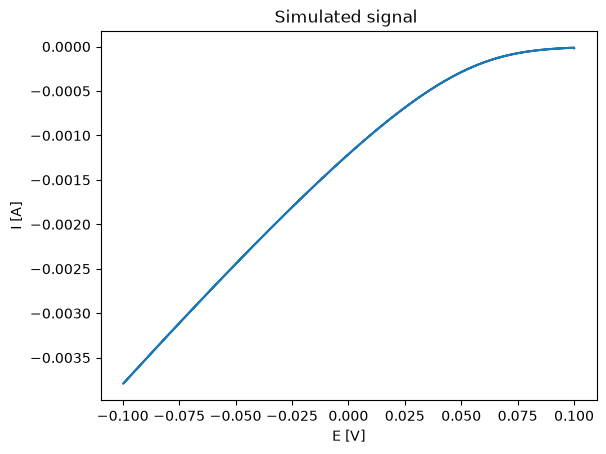

In [2]:
mechanism = "E(1): *=H* \n C: H*+H* > * + *"

kin = [[0.5, 2000, 0.00],
 [100000000]]

D=[]

cell_c=[293, 30, 0.01, 1.96*10**-5]

si=[0.0001, 20, 10**-5, 0]

spec_info=[[1*10**-5, 0], []]

iso = [0, 0]

Ei=0.1 
Ef=-0.1
v=0.01   
freq=0
amp=0.0  
nt=1000 

sim = ElectroKitty(mechanism)
sim.V_potential(Ei, Ef, v, 0, 0, nt)
sim.create_simulation(kin, cell_c, D, iso, si, spec_info)
sim.simulate()
sim.Plot_simulation()

It might not look exactly like measured data, but it is close enough so that we can use it. The most important thing is that our "data" has a problem with uncompensated resistance. While 30 $\Omega$s might not be a high value, at such high currents the effect is quite significant. Notice how the potential-current curve starts to become linear at lower potentials. Let us try and deal with such data using ElectroKitty.

First we need to save our data. It should be noted that ElectroKitty cannot by itself save data, but it can save itself, something which will be useful in the next tutorial. Since we will consider this simulated voltammogram as experimental data we must save our simulation in another way. Luckilly numpy exists...

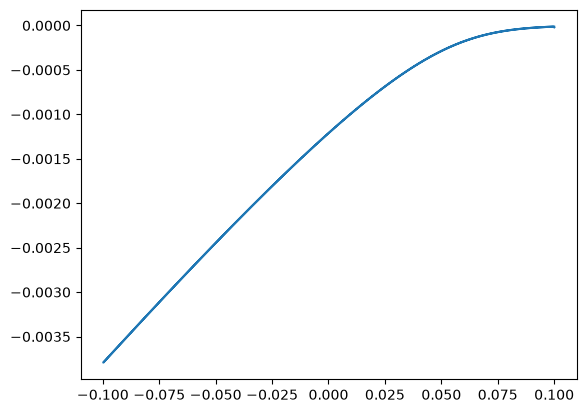

In [3]:
arr = np.array([sim.E_generated, sim.current, sim.t]) # we create a numpy array in a potential current time format, this is important for later

np.savetxt("HER_sim.txt", arr.T) # using numpy to save our data in a txt file, retaining our format

data = np.loadtxt("HER_sim.txt") # loading our data to make a quick check if everything was saved correctly

plt.plot(data[:,0], data[:,1]) # the check


# Importing data

Now we need to input our data to ElectroKitty so that it can work on it. Here we have two options. 

1. use the set_data function and input it manually
2. import the data directly from the .txt file, but the data must striclty follow the potential, current, time format and be delimited by a tab

Whatever method you choose to use, will mostly depend on how your potentiostat saves data. Since the programs used to run potentiostats export their data in different formats, importing data separately and then using option 1 is often the best way of doing things.

For option 1 we need to create 3 separate numpy arrays: one for the potential, one for the current and one for the time. If we can supply ElectroKitty with these 3 arrays, we should be good to go.

For option 2 we need a txt file in the correct format and lucky for us numpy arranges it exactly the way we need it. The txt file need not be perfect. We can tell ElectroKitty to skip lines in the file, but the data saving format is a must, or risk simulating nonsense!


Here we will demonstrate both versions, as we already have a convenient txt file to work with. We will create a new class and show the functions...

Note: if you are only dealing with data, passing a mechanism at the start is not neccessary.

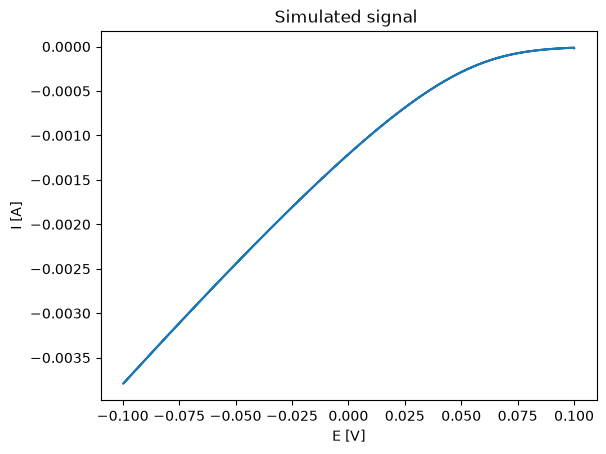

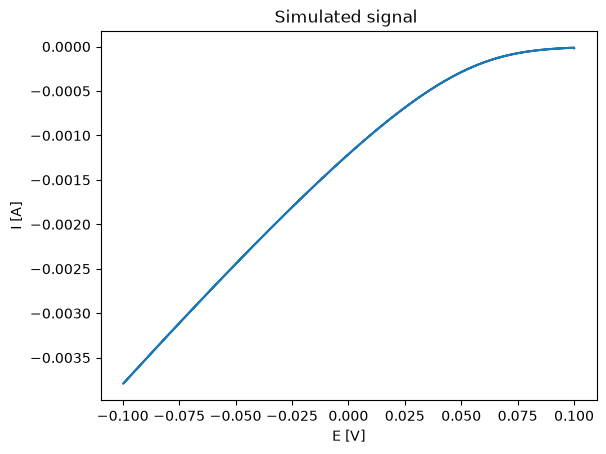

In [4]:
problem = ElectroKitty()

# importing our data again just to be safe
data = np.loadtxt("HER_sim.txt")

# creating the arrays and passing them to electrokitty
E_data = data[:,0]
i_data = data[:,1]
t_data = data[:,2]

problem.set_data(E_data, i_data, t_data)

# let us plot it to check that we were successful
problem.Plot_data()

# showing off the more direct path
# this will override the previoussly imported data, but here we do not care for it

problem.load_data_from_txt("HER_sim.txt", skip = 0)
problem.Plot_data()

# IR correcting our data

With the data now imported let us now correct it for IR. We need to call the IR_correct_data. This function can either correct our data or simulation, depending on what we choose. We just need to pass it the resistance value to correct for and what data to correct the potential. The class generates the corrected potential, which we can then plot with.

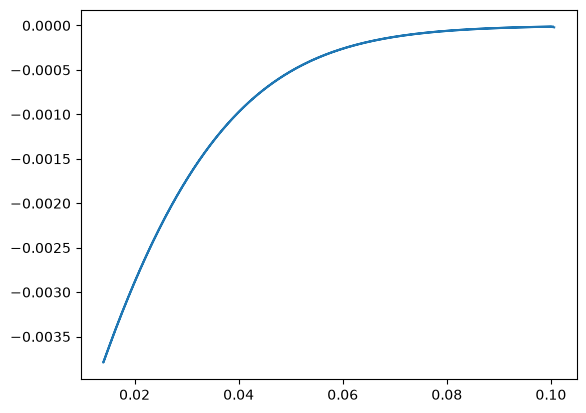

In [5]:
problem.IR_correct_data(Ru = 30, correct_data = True) # calling to correct the data

plt.plot(problem.E_corrected, problem.I_data) # a simple plot of the correction

We see that the effect is very problematic...

The same can be done with a simulation. While not as useful (you can just set the Ru constant to 0), it can be interesting to explore the influence of correction.

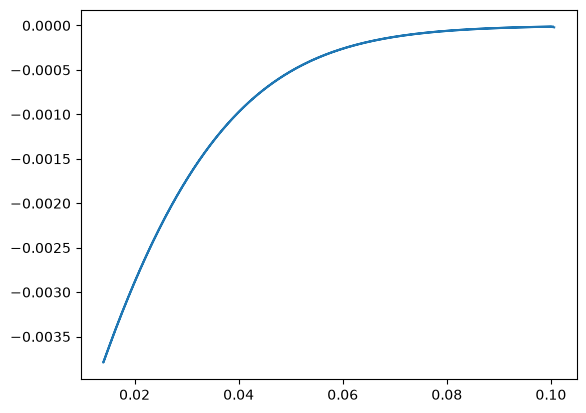

In [6]:
sim.IR_correct_data(Ru = 30, correct_simulation = True) # now we are correcting the simulation

plt.plot(sim.E_corrected, sim.current) # a simple plot of the correction

# FFT analysis for the FTACV

This is a more specialized topic than the one discussed before since you need to be familiar with the technique for the next part to be useful. 

ElectroKitty offers a very simple way of extracting the harmonic envelope currents from the data. For this we will again need a simulation. We will be demonstrating a simple surface-confined 1e reaction. Here is the code to simulate it.

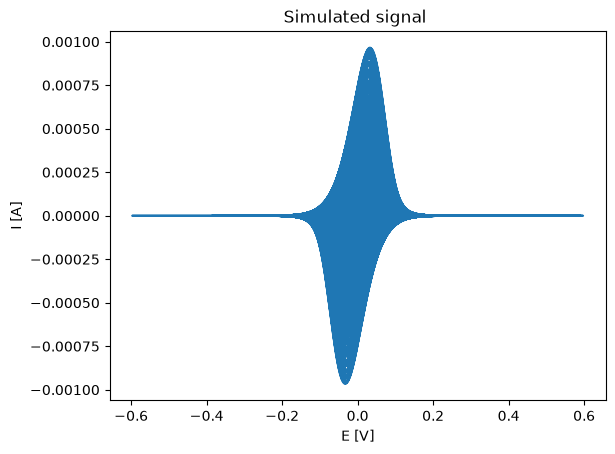

In [7]:
mechanism = "E(1): a*=b*"

kin = [[0.5, 100, 0.00]]

D=[]

cell_c=[293, 0, 0, 1.96*10**-5]

si=[0.0001, 20, 10**-5, 0]

spec_info=[[1*10**-5, 0], []]

iso = [0, 0]

Ei=0.5
Ef=-0.5
v=0.1   
freq=9 # frequency of the sine wave [Hz]
amp=0.1  # amplitude of the sine wave [V]
nt=2**16

sim = ElectroKitty(mechanism)
sim.V_potential(Ei, Ef, v, amp, freq, nt) # adding both to signal generation
sim.create_simulation(kin, cell_c, D, iso, si, spec_info)
sim.simulate()
sim.Plot_simulation()

Now that we have our signal we need to treat it. In ElectroKitty this is done by one function call. The function FFT_analyze_data/sim creates a FT of our data and based on our window range (electrokitty uses rectangular window functions), will generate the harmonic envelopes.

Since we have a simulation we need to make the appropriate call...

In [8]:
N_harmonics = 5 # we want 5 harmonics, so electrokitty will generate the zeroth + 5
windows = 0.1*freq*np.ones(N_harmonics+1) # the +1 is for the 0th harmonic. Nothing will break if you create more windows

sim.FFT_analyze_sim(freq, N_harmonics, windows) # calling the correct function

Let us now plot our transformed data.
First the FT.

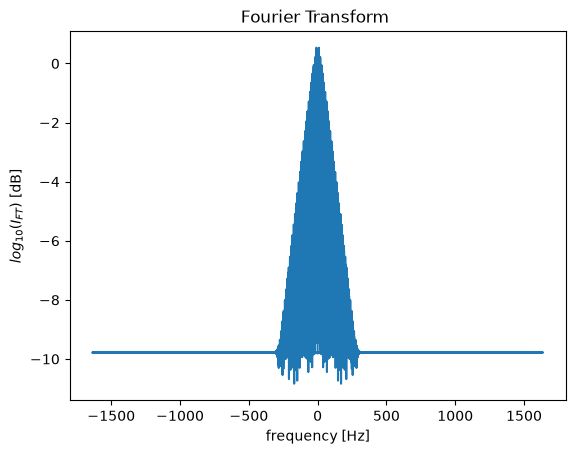

In [9]:
sim.FT_plot()

Second the harmonics. Each harmonic will be it's own separate plot. 

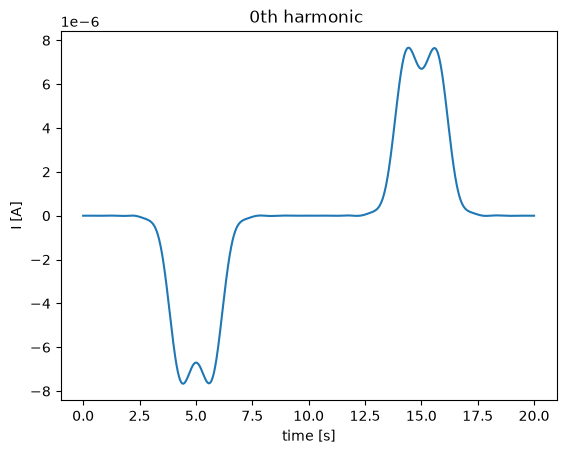

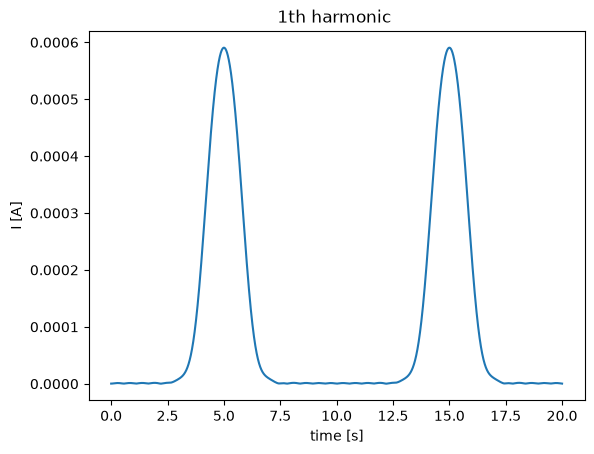

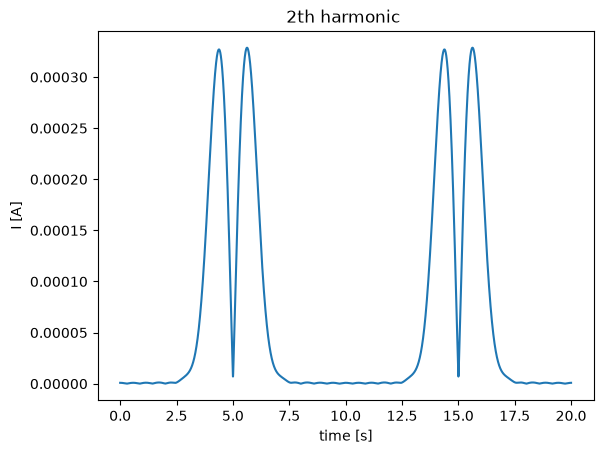

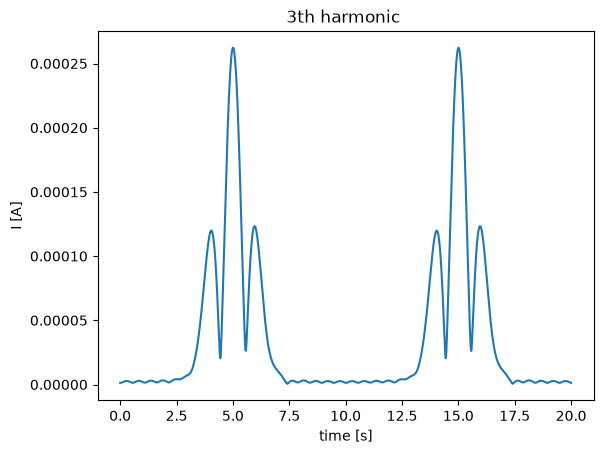

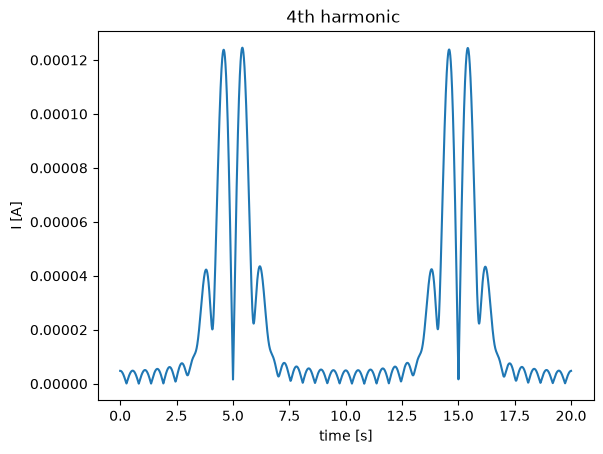

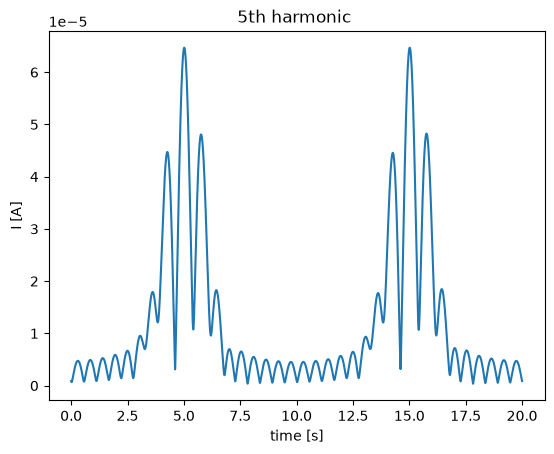

In [10]:
sim.Harmonic_plots(plot_sim = True) # for this function we must declare whether to plot a simulation or experiment

# sim.Harmonic_plots(plot_data = True) would plot the experiment, but we do not have it here

With this we have concluded a tutorial on how to treat data with ElectroKitty. The main take away here is the tutorial on importing data, as that will be important in the next and last tutorial in data fitting.